# Bài Lab: Laplacian of Gaussian Edge Detector
## Mục tiêu
Phát hiện biên bằng phương pháp Laplacian of Gaussian (LoG) trong Thị giác Máy tính. Phương pháp này kết hợp bộ lọc Gaussian để giảm nhiễu và toán tử Laplacian để phát hiện các điểm thay đổi cường độ (cạnh). Các giai đoạn chính như sau:

1. Làm mịn ảnh bằng bộ lọc Gaussian.
2. Áp dụng toán tử Laplacian để tính đạo hàm bậc hai.
3. Phát hiện các điểm giao zero (zero-crossing) để xác định biên.

Thư viện sử dụng: NumPy, SciPy, và Matplotlib

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy import ndimage
from scipy.ndimage import convolve

import os

def read_image(input_img):
    supported_formats = ['.bmp', '.jpg', '.jpeg', '.png']

    # Nếu không có đuôi file → thử nối các phần mở rộng
    if not os.path.splitext(input_img)[1]:
        for fmt in supported_formats:
            test_path = input_img + fmt
            if os.path.exists(test_path):
                print(f"Đọc ảnh: {test_path}")
                return mpimg.imread(test_path)
        print("❌ Không tìm thấy ảnh với bất kỳ định dạng hợp lệ nào.")
        return None
    else:
        if os.path.exists(input_img):
            print(f"Đọc ảnh: {input_img}")
            return mpimg.imread(input_img)
        else:
            print("❌ Đường dẫn không tồn tại.")
            return None


## Phần 1: Tính Gradient (Smoothed Gradients)
Mục tiêu là giảm nhiễu và tính toán gradient của ảnh để phát hiện các điểm có sự thay đổi cường độ lớn (cạnh).

### Yêu cầu
1. **Chuyển ảnh màu sang thang độ xám:**
   - Nếu ảnh đầu vào là ảnh RGB, chuyển sang thang độ xám để đơn giản hóa xử lý.

2. **Làm mịn ảnh bằng bộ lọc Gaussian:**
   - Áp dụng tích chập với Gaussian $(𝜎 = 1)$ để giảm nhiễu.

3. **Tính gradient theo hướng x và y:**
   - Dùng toán tử Sobel để tính $𝐼ₓ$ (gradient ngang) và $𝐼ᵧ$ (gradient dọc).

4. **Tính độ lớn và hướng gradient:**
   - Độ lớn gradient: $𝐹 = √(𝐼ₓ² + 𝐼ᵧ²)$.
   - Hướng gradient: $𝐷 = arctan(𝐼ᵧ / 𝐼ₓ)$.

### Công thức

1. **Gaussian Kernel $(𝜎 = 1)$:**
   $$
   G(x,y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2 + y^2}{2\sigma^2}}
   $$
   Ma trận 3x3 xấp xỉ:
   $$
   G = \begin{bmatrix}
   0.1019 & 0.1154 & 0.1019 \\
   0.1154 & 0.1308 & 0.1154 \\
   0.1019 & 0.1154 & 0.1019
   \end{bmatrix}
   $$

2. **Toán tử Sobel:**
   $$
   Sₓ = \begin{bmatrix}
   -1 & 0 & 1 \\
   -2 & 0 & 2 \\
   -1 & 0 & 1
   \end{bmatrix}, \quad Sᵧ = \begin{bmatrix}
   1 & 2 & 1 \\
   0 & 0 & 0 \\
   -1 & -2 & -1
   \end{bmatrix}
   $$

3. **Gradient:**
   $$
   Iₓ = I * Sₓ, \quad Iᵧ = I * Sᵧ
   $$
   $$
   F = \sqrt{Iₓ² + Iᵧ²}, \quad D = \arctan{\left(\frac{Iᵧ}{Iₓ}\right)}
   $$





In [13]:
def rgb2gray(img):
    """
    Chuyển đổi ảnh RGB sang xám:
    Y = 0.2989R + 0.5870G + 0.1140B
    """
    if img.ndim == 3:
        return np.dot(img[...,:3], [0.2989, 0.5870, 0.1140])
    return img


def gaussian_kernel(size, sigma):
    """
    Tạo Gaussian kernel 2D với kích thước size x size và độ lệch chuẩn sigma.
    """
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2. * sigma**2))
    return kernel / np.sum(kernel)
   # Chuẩn hóa kernel


## Phần 2: Áp dụng toán tử Laplacian

Laplacian được áp dụng lên ảnh đã làm mịn để tính đạo hàm bậc hai, nhằm xác định các điểm thay đổi cường độ lớn (cạnh). Laplacian nhạy với nhiễu, do đó bước làm mịn trước đó là cần thiết.

### Yêu cầu
**Tính Laplacian:**
- Sử dụng kernel Laplacian hoặc hàm tích chập có sẵn trong SciPy (`ndimage.laplace`).

**Kết hợp Gaussian và Laplacian (LoG):**
- Thay vì làm mịn rồi tính Laplacian riêng lẻ, có thể kết hợp trực tiếp thành Laplacian of Gaussian kernel.

### Công thức

**Toán tử Laplacian:**

$$
∇^2 I = \frac{\partial^2 I}{\partial x^2} + \frac{\partial^2 I}{\partial y^2}
$$

**Kernel Laplacian đơn giản (3x3):**

$$
L =
\begin{bmatrix}
0 & 1 & 0 \\
1 & -4 & 1 \\
0 & 1 & 0
\end{bmatrix}
$$

**Laplacian of Gaussian (LoG):**

$$
LoG(x,y) = -\frac{1}{\pi \sigma^4} \left[ 1 - \frac{x^2 + y^2}{2\sigma^2} \right] e^{-\frac{x^2 + y^2}{2\sigma^2}}
$$


In [17]:
def log_kernel(size, sigma):
    """
    Tạo Laplacian of Gaussian kernel 2D với kích thước (size x size) và độ lệch chuẩn sigma.
    """
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)

    r2 = xx**2 + yy**2
    norm = (r2 - 2 * sigma**2) / (sigma**4)
    kernel = norm * np.exp(-r2 / (2 * sigma**2))

    kernel -= kernel.mean()

    return kernel.astype(np.float32)


## Phần 3: Phát hiện Zero-crossing
Sau khi áp dụng LoG, các biên được xác định bằng cách tìm các điểm giao zero (zero-crossing) trong ảnh kết quả. (Đây là vị trí đạo hàm bậc hai thay đổi dấu.)

### Yêu cầu

**Xác định zero-crossing:**
- Kiểm tra các pixel lân cận (ví dụ: 4 hoặc 8 lân cận) để phát hiện sự thay đổi dấu.

**Tạo ảnh biên:**
- Gán giá trị 1 cho các điểm zero-crossing (cạnh), 0 cho các điểm khác.

### Công thức
Một pixel (x, y) là zero-crossing nếu có ít nhất một cặp lân cận đối diện (theo hướng ngang, dọc hoặc chéo) có tích âm:

$$
I(x, y) \cdot I(x', y') < 0
$$


In [15]:
def zero_crossing(img):
    """
    Phát hiện các điểm zero-crossing trong ảnh LoG.
    Trả về ảnh nhị phân với các pixel biên có giá trị 1 (trắng), còn lại là 0 (đen).
    """
    edge_img = np.zeros(img.shape, dtype=np.float32)
    rows, cols = img.shape

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):
            patch = img[i-1:i+2, j-1:j+2]  # 3x3 vùng lân cận
            p = img[i, j]
            min_val = patch.min()
            max_val = patch.max()
            
            # Nếu pixel nằm giữa giá trị âm và dương, tức là có điểm giao zero
            if p > 0 and min_val < 0:
                edge_img[i, j] = 1
            elif p < 0 and max_val > 0:
                edge_img[i, j] = 1

    return edge_img



## Phần 4: thực hiện LoG

Đọc ảnh: aircarft.png


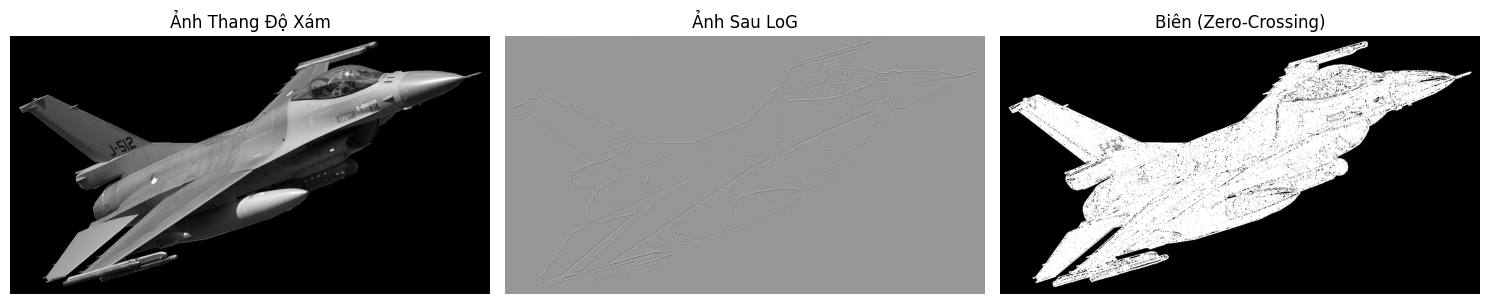

In [18]:
def process_image(input_img, sigma=1.0, kernel_size=5):
    """
    Đọc ảnh, chuyển xám, làm mịn, áp dụng LoG, phát hiện biên.
    """
    img_rgb = read_image(input_img)
    if img_rgb is None:
        raise FileNotFoundError(f"Không tìm thấy ảnh với tên: {input_img}")

    # 1. Chuyển xám
    img_gray = rgb2gray(img_rgb)

    # 2. Làm mịn ảnh bằng Gaussian trước khi áp dụng Laplacian
    log_k = log_kernel(kernel_size, sigma)

    # 3. Áp dụng LoG kernel (tích chập)
    log_img = convolve(img_gray, log_k)

    # 4. Phát hiện biên bằng zero-crossing
    edge_img = zero_crossing(log_img)

    # 5. Lưu và hiển thị kết quả
    output_dir = 'Results/log_edge/'
    os.makedirs(output_dir, exist_ok=True)

    plt.imsave(os.path.join(output_dir, input_img + '_gray.jpg'), img_gray, cmap='gray')
    plt.imsave(os.path.join(output_dir, input_img + '_log.jpg'), log_img, cmap='gray')
    plt.imsave(os.path.join(output_dir, input_img + '_edges.jpg'), edge_img, cmap='gray')

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_gray, cmap='gray')
    axes[0].set_title("Ảnh Thang Độ Xám")
    axes[0].axis('off')

    axes[1].imshow(log_img, cmap='gray')
    axes[1].set_title("Ảnh Sau LoG")
    axes[1].axis('off')

    axes[2].imshow(edge_img, cmap='gray')
    axes[2].set_title("Biên (Zero-Crossing)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

# Gọi hàm
input_img = 'aircarft.png'
process_image(input_img, sigma=1.0, kernel_size=5)
